# **2. Motivos de Cartões e Atrasos: BERTopic Two-Pass, Fine-Tuning e Classificação**

Responsabilidade deste notebook:

- carregar `data/processed/card_reasons.csv` e `data/processed/delay_reasons.csv`, gerados no notebook 1;
- usar somente a justificativa livre do árbitro em `reason` para motivos de cartão;
- gerar embeddings com modelo base e rodar BERTopic **Pass 1** para obter clusters iniciais a partir dos dados, sem nenhuma regra manual;
- fine-tunar um `sentence-transformers` usando pares positivos extraídos dos clusters da Pass 1;
- rodar BERTopic **Pass 2** com o modelo fine-tunado e inspecionar os clusters emergentes;
- mapear clusters → grupos semânticos via dicionário `TOPIC_TO_GROUP` preenchido manualmente após inspeção;
- explorar `delay_reasons` com BERTopic e marcar partidas em que o texto indica uso/checagem/revisão de VAR.

## **1. Configuração**

In [1]:
import re
import unicodedata
from itertools import combinations
from pathlib import Path

import hdbscan
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import umap
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from sentence_transformers import models as st_models
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_colwidth", 220)
plt.style.use("seaborn-v0_8-whitegrid")

/Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/var/folders/x8/hw9x5p0d1v9bjf56_4xc8qrh0000gn/T/ipykernel_57903/2946998003.py:13: DeprecationWarning: Importing from 'sentence_transformers.models' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.modules' instead.
  from sentence_transformers import models as st_models


In [2]:
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
DATA_PATH = PROJECT_ROOT / "data"
PROCESSED_PATH = DATA_PATH / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = PROCESSED_PATH / "semantic_reasons"
CARD_OUTPUT_DIR = OUTPUT_DIR / "card_reasons"
DELAY_OUTPUT_DIR = OUTPUT_DIR / "delay_reasons"

CARD_REASONS_PATH = PROCESSED_PATH / "card_reasons.csv"
DELAY_REASONS_PATH = PROCESSED_PATH / "delay_reasons.csv"

for directory in [MODELS_DIR, OUTPUT_DIR, CARD_OUTPUT_DIR, DELAY_OUTPUT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

MODEL_NAME = "sentence-transformers/paraphrase-multilingual-mpnet-base-v2"
# Two-pass: fine-tunado sobre clusters emergentes (sem regras de palavras-chave)
FINETUNED_MODEL_DIR = MODELS_DIR / "football_card_reason_embeddings_two_pass"

RUN_FINE_TUNING = True
RETRAIN_FINETUNED_MODEL = False
USE_FINETUNED_IF_AVAILABLE = True
FINETUNE_EPOCHS = 1
FINETUNE_BATCH_SIZE = 32
MAX_TEXTS_PER_GROUP_FOR_FINETUNE = 220
MAX_TEXT_PAIRS_PER_GROUP_FOR_FINETUNE = 450

CARD_MIN_TOPIC_SIZE = 45
CARD_MIN_SAMPLES = 12
DELAY_MIN_TOPIC_SIZE = 35
DELAY_MIN_SAMPLES = 8
BERTOPIC_NGRAM_RANGE = (1, 3)

CARD_TEXT_COLUMN = "card_reason_text"
CARD_TEXT_KEY_COLUMN = "card_reason_text_key"
DELAY_TEXT_COLUMN = "delay_reason_clean"

## **2. Carregamento dos Dados Limpos**

Para cartões, a única coluna textual usada é `reason`, que no notebook 1 passa a ser a justificativa escrita pelo árbitro após o separador ` - `.

In [3]:
REQUIRED_CARD_COLUMNS = {
    "year", "round", "game_id", "game_number", "match_date", "home_team", "away_team", "arbitro",
    "card_type", "team", "minute", "half", "reason", "reason_key",
}
REQUIRED_DELAY_COLUMNS = {
    "year", "round", "game_id", "game_number", "match_date", "home_team", "away_team", "arbitro", "delay_reason",
}

cards = pd.read_csv(CARD_REASONS_PATH, keep_default_na=False)
delays = pd.read_csv(DELAY_REASONS_PATH, keep_default_na=False)

missing_cards = REQUIRED_CARD_COLUMNS.difference(cards.columns)
missing_delays = REQUIRED_DELAY_COLUMNS.difference(delays.columns)
if missing_cards:
    raise ValueError(f"Colunas ausentes em {CARD_REASONS_PATH.name}: {sorted(missing_cards)}")
if missing_delays:
    raise ValueError(f"Colunas ausentes em {DELAY_REASONS_PATH.name}: {sorted(missing_delays)}")

cards.head(3)

,year,round,game_id,game_number,match_date,home_team,away_team,arbitro,card_type,team,minute,half,reason,reason_key
0,2020,1,812497,1,2019-04-27,Guarani,Figueirense,Luiz César de Oliveira Magalhães,yellow,Figueirense,7,1T,Por dar uma rasteira em seu adversário de maneira temerária na disputa da bola.,por dar uma rasteira em seu adversario de maneira temeraria na disputa da bola.
1,2020,1,812497,1,2019-04-27,Guarani,Figueirense,Luiz César de Oliveira Magalhães,yellow,Guarani,15,1T,Por dar uma rasteira em seu adversário de maneira temerária na disputa da bola.,por dar uma rasteira em seu adversario de maneira temeraria na disputa da bola.
2,2020,1,815072,1,2020-08-09,Flamengo,Atlético Mineiro,Raphael Claus,yellow,Atlético Mineiro,18,1T,Por reclamar ostensivamente com palavras e gestos.,por reclamar ostensivamente com palavras e gestos.


In [4]:
def normalize_text(text: str) -> str:
    text = unicodedata.normalize("NFKD", str(text))
    text = "".join(char for char in text if not unicodedata.combining(char))
    text = text.casefold()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


cards[CARD_TEXT_COLUMN] = cards["reason"].fillna("").astype(str).str.strip()
cards[CARD_TEXT_KEY_COLUMN] = cards[CARD_TEXT_COLUMN].map(normalize_text)
cards = cards[cards[CARD_TEXT_KEY_COLUMN].ne("")].reset_index(drop=True)

delays[DELAY_TEXT_COLUMN] = delays["delay_reason"].fillna("").astype(str).str.strip()
delays[DELAY_TEXT_COLUMN] = delays[DELAY_TEXT_COLUMN].where(delays[DELAY_TEXT_COLUMN].ne(""), "n/a")
delays["delay_reason_key"] = delays[DELAY_TEXT_COLUMN].map(normalize_text)

pd.Series({
    "card_rows": len(cards),
    "unique_card_reason_texts": cards[CARD_TEXT_KEY_COLUMN].nunique(),
    "delay_rows": len(delays),
    "unique_delay_reason_texts": delays["delay_reason_key"].nunique(),
    "delay_na": delays[DELAY_TEXT_COLUMN].eq("n/a").sum(),
})

card_rows                    25752
unique_card_reason_texts      6940
delay_rows                    5663
unique_delay_reason_texts     3765
delay_na                        52
dtype: int64

## **3. Textos de Cartão Mais Recorrentes**

Esta leitura inicial mostra quais justificativas livres aparecem com mais frequência antes de qualquer embedding.

In [5]:
card_text_counts = (
    cards.groupby(CARD_TEXT_KEY_COLUMN)
    .agg(
        text_for_embedding=(CARD_TEXT_COLUMN, "first"),
        n_events=(CARD_TEXT_COLUMN, "size"),
        n_yellow=("card_type", lambda values: (values == "yellow").sum()),
        n_red=("card_type", lambda values: (values == "red").sum()),
    )
    .reset_index()
    .sort_values("n_events", ascending=False)
    .reset_index(drop=True)
)

card_texts = card_text_counts["text_for_embedding"].tolist()

card_text_counts.head(25)

,card_reason_text_key,text_for_embedding,n_events,n_yellow,n_red
0,por calcar seu adversario de maneira temeraria na disputa de bola,Por calçar seu adversário de maneira temerária na disputa de bola.,500,500,0
1,por cometer uma falta tatica impedindo um ataque promissor,"Por cometer uma falta tática, impedindo um ataque promissor.",410,410,0
2,por retardar o reinicio de jogo,Por retardar o reinicio de jogo,333,333,0
3,cometer uma falta tatica para impedir um ataque promissor,Cometer uma falta tática para impedir um ataque promissor.,285,284,1
4,por cometer uma falta tatica para impedir um ataque promissor,Por cometer uma falta tática para impedir um ataque promissor.,248,247,1
5,por calcar seu adversario de maneira temeraria na disputa da bola,"Por calçar seu adversário de maneira temerária, na disputa da bola",236,236,0
6,por calcar seu adversario de forma temeraria na disputa de bola,Por calçar seu adversário de forma temerária na disputa de bola.,228,228,0
7,dar uma entrada contra um adversario de maneira temeraria na disputa da bola,Dar uma entrada contra um adversário de maneira temerária na disputa da bola.,224,223,1
8,por reclamar contra as decisoes da arbitragem,Por reclamar contra as decisões da arbitragem.,202,202,0
9,por impedir um ataque promissor,Por impedir um ataque promissor.,202,202,0


In [6]:
PORTUGUESE_STOPWORDS = {
    "a", "ao", "aos", "as", "com", "como", "da", "das", "de", "do", "dos", "e", "em", "na", "nas",
    "no", "nos", "o", "os", "ou", "para", "por", "que", "se", "sem", "um", "uma", "uns", "umas",
    "apos", "ate", "contra", "durante", "forma", "maneira", "motivo", "pela", "pelo", "pelas", "pelos",
    "num", "numa", "ter", "tendo", "dado", "haver", "havendo", "advertido", "advertida", "advertir",
    "adversario", "adversaria", "atleta", "jogador", "jogadora", "sr", "sra", "numero", "n", "equipe",
    "bola", "campo", "disputa", "jogada", "jogo", "partida", "seu", "sua", "seus", "suas", "foi", "foram",
    "acrescimo", "acrescimos", "devido", "inicio", "reinicio", "tempo", "minuto", "minutos", "jogadores",
}


def make_topic_model(min_topic_size: int, min_samples: int, n_neighbors: int = 20, n_components: int = 5) -> BERTopic:
    vectorizer_model = CountVectorizer(
        stop_words=list(PORTUGUESE_STOPWORDS),
        ngram_range=BERTOPIC_NGRAM_RANGE,
        min_df=2,
    )
    umap_model = umap.UMAP(
        n_neighbors=n_neighbors,
        n_components=n_components,
        min_dist=0.0,
        metric="cosine",
        random_state=RANDOM_STATE,
    )
    hdbscan_model = hdbscan.HDBSCAN(
        min_cluster_size=min_topic_size,
        min_samples=min_samples,
        metric="euclidean",
        prediction_data=True,
    )
    return BERTopic(
        language="multilingual",
        embedding_model=None,
        umap_model=umap_model,
        hdbscan_model=hdbscan_model,
        vectorizer_model=vectorizer_model,
        calculate_probabilities=False,
        verbose=False,
    )


def topic_words(topic_model: BERTopic, topic_id: int, top_n: int = 8) -> str:
    if topic_id == -1:
        return "outliers"
    words = topic_model.get_topic(topic_id) or []
    return ", ".join(word for word, _ in words[:top_n])


def build_topic_summary(topic_model: BERTopic, text_counts: pd.DataFrame, topic_col: str) -> pd.DataFrame:
    topic_info = topic_model.get_topic_info().rename(columns={"Topic": topic_col})
    event_counts = (
        text_counts.groupby(topic_col)
        .agg(
            n_unique_texts=("text_for_embedding", "size"),
            n_events=("n_events", "sum"),
        )
        .reset_index()
    )
    summary = topic_info.merge(event_counts, on=topic_col, how="left")
    summary["top_terms"] = summary[topic_col].map(lambda topic_id: topic_words(topic_model, int(topic_id)))
    return summary.sort_values("n_events", ascending=False).reset_index(drop=True)


def top_examples_by_topic(
    text_counts: pd.DataFrame,
    topic_col: str,
    top_n: int = 5,
) -> pd.DataFrame:
    columns = [topic_col, "n_events", "text_for_embedding"]
    return (
        text_counts.sort_values([topic_col, "n_events"], ascending=[True, False])
        .groupby(topic_col)
        .head(top_n)
        [columns]
        .reset_index(drop=True)
    )

## **4. Modelo Base e BERTopic Pass 1**

O fine-tuning usa duas passagens para não introduzir viés de regras manuais:

- **Pass 1**: modelo base gera embeddings → BERTopic agrupa → clusters emergem dos dados
- **Fine-tuning**: pares positivos construídos a partir dos clusters da Pass 1, sem palavras-chave
- **Pass 2**: modelo fine-tunado → BERTopic final → inspecione e rotule os clusters manualmente

In [7]:
def load_embedding_model(model_name_or_path) -> SentenceTransformer:
    """Carrega SentenceTransformer nativo ou BERT puro com mean pooling."""
    path = str(model_name_or_path)
    try:
        model = SentenceTransformer(path)
        print(f"[OK] SentenceTransformer: {path}")
        return model
    except Exception:
        word_model = st_models.Transformer(path, max_seq_length=256)
        pooling = st_models.Pooling(
            word_model.get_word_embedding_dimension(),
            pooling_mode_mean_tokens=True,
        )
        model = SentenceTransformer(modules=[word_model, pooling])
        print(f"[OK] Transformer + mean pooling: {path}")
        return model


def model_dir_ready(path: Path) -> bool:
    return (path / "modules.json").exists()


base_model = load_embedding_model(MODEL_NAME)

base_card_embeddings = base_model.encode(
    card_texts,
    show_progress_bar=True,
    normalize_embeddings=True,
    batch_size=64,
)
base_card_embeddings = np.asarray(base_card_embeddings)
print(f"Embeddings base (Pass 1): {base_card_embeddings.shape}")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8933.32it/s]


[OK] SentenceTransformer: sentence-transformers/paraphrase-multilingual-mpnet-base-v2


Batches: 100%|██████████| 109/109 [00:11<00:00,  9.42it/s]

Embeddings base (Pass 1): (6940, 768)


In [9]:
card_topic_model_pass1 = make_topic_model(
    min_topic_size=CARD_MIN_TOPIC_SIZE,
    min_samples=CARD_MIN_SAMPLES,
    n_neighbors=25,
    n_components=5,
)
card_topics_pass1, _ = card_topic_model_pass1.fit_transform(
    card_texts, embeddings=base_card_embeddings
)
card_text_counts["bertopic_topic_pass1"] = card_topics_pass1

_pass1_summary = build_topic_summary(
    card_topic_model_pass1,
    card_text_counts.rename(columns={"bertopic_topic_pass1": "bertopic_topic"}),
    "bertopic_topic",
).rename(columns={"bertopic_topic": "bertopic_topic_pass1"})

print(f"Pass 1 — clusters encontrados: {_pass1_summary['bertopic_topic_pass1'].ne(-1).sum()}")
_pass1_summary.head(20)

Pass 1 — clusters encontrados: 55


,bertopic_topic_pass1,Count,Name,Representation,Representative_Docs,n_unique_texts,n_events,top_terms
0,4,211,4_entrada_dar entrada_entrada temerária adversário_entrada temerária,"[entrada, dar entrada, entrada temerária adversário, entrada temerária, adversário dar entrada, dar, adversário dar, dar entrada temerária, temerária adversário, temerária adversário dar]","[Por dar uma entrada temerária contra o seu adversário na disputa da bola., Por dar uma entrada de forma temerária no adversário, na disputa da bola., Por dar uma entrada de maneira temerária contra o adversário na d...",211,2341,"entrada, dar entrada, entrada temerária adversário, entrada temerária, adversário dar entrada, dar, adversário dar, dar entrada temerária"
1,23,98,23_calçar_calçar adversário_calçar adversário temerária_temerária calçar,"[calçar, calçar adversário, calçar adversário temerária, temerária calçar, temerária calçar adversário, adversário temerária calçar, adversário calçar, adversário calçar adversário, adversário temerária, temerária]","[Por calçar um seu adversário de maneira temerária na disputa de bola., Por calçar seu adversário maneira temerária na disputa de bola., Por na disputa de bola calçar o seu adversário de maneira temerária.]",98,2107,"calçar, calçar adversário, calçar adversário temerária, temerária calçar, temerária calçar adversário, adversário temerária calçar, adversário calçar, adversário calçar adversário"
2,12,120,12_promissor cometer_ataque promissor cometer_ataque_promissor cometer falta,"[promissor cometer, ataque promissor cometer, ataque, promissor cometer falta, promissor, ataque promissor, impedir ataque, impedir ataque promissor, impedir, cometer falta]","[Por cometer uma falta tática para impedir uma ataque promissor., Cometer falta tática para impedir um ataque promissor., Por cometer uma falta tática para impedir um ataque promissor.]",120,1716,"promissor cometer, ataque promissor cometer, ataque, promissor cometer falta, promissor, ataque promissor, impedir ataque, impedir ataque promissor"
3,-1,648,-1_reclamar_arbitragem_técnica_área técnica,"[reclamar, arbitragem, técnica, área técnica, área, decisões, decisões arbitragem, autorização, entrar, lateral]","[Por sair da sua área técnica persistentemente., Por sair de sua área técnica e reclamar de maneira acintosa contra as decisões da arbitragem., Por entrar no campo de jogo, sem autorização para reclamar acintosamernt...",648,1502,outliers
4,9,131,9_dar entrada_entrada_dar entrada adversário_entrada adversário,"[dar entrada, entrada, dar entrada adversário, entrada adversário, dar, adversário dar entrada, temerária dar entrada, entrada adversário temerária, adversário dar, dar entrada temerária]","[Dar uma entrada contra seu adversário de forma temerária na disputa da bola., Dar uma entrada contra uma adversário de maneira temerária na disputa da bola., Dar uma entrada em seu adversário de forma temerária na d...",131,1353,"dar entrada, entrada, dar entrada adversário, entrada adversário, dar, adversário dar entrada, temerária dar entrada, entrada adversário temerária"
5,6,185,6_desaprovar_arbitragem desaprovar_decisões arbitragem desaprovar_gestos,"[desaprovar, arbitragem desaprovar, decisões arbitragem desaprovar, gestos, desaprovar palavras, arbitragem desaprovar palavras, palavras, arbitragem, decisões, decisões arbitragem]","[Por desaprovar com palavras e gestos as decisões da arbitragem., Por desaprovar com palavras ou gestos das decisões da arbitragem., Desaprovar com palavras e gestões as decisões da arbitragem.]",185,1285,"desaprovar, arbitragem desaprovar, decisões arbitragem desaprovar, gestos, desaprovar palavras, arbitragem desaprovar palavras, palavras, arbitragem"
6,2,262,2_dar_temerária_entrada_dar entrada,"[dar, temerária, entrada, dar entrada, adversário temerária, temerária dar, adversário, temeraria, temerária adversário, temerária dar entrada]","[Por dar uma entrada de maneira temerária no adversário., Por dar uma entrada temerária em 

## **5. Fine-Tuning a Partir dos Clusters da Pass 1**

Os pares positivos são construídos a partir dos clusters emergentes do BERTopic Pass 1 — sem nenhuma regra de palavras-chave. Textos do mesmo cluster são tratados como semanticamente equivalentes, ajustando o espaço de embeddings ao domínio das súmulas sem impor categorias pré-definidas.

In [10]:
def build_pairs_from_clusters(
    text_counts: pd.DataFrame,
    topic_col: str,
    max_texts: int = MAX_TEXTS_PER_GROUP_FOR_FINETUNE,
    max_pairs: int = MAX_TEXT_PAIRS_PER_GROUP_FOR_FINETUNE,
) -> list[dict]:
    pairs: list[dict] = []
    for _, group in text_counts[text_counts[topic_col].ne(-1)].groupby(topic_col):
        texts = (
            group.sort_values("n_events", ascending=False)["text_for_embedding"]
            .dropna()
            .astype(str)
            .str.strip()
            .loc[lambda v: v.ne("")]
            .drop_duplicates()
            .head(max_texts)
            .tolist()
        )
        pairs.extend(
            {"anchor": left, "positive": right}
            for left, right in list(combinations(texts, 2))[:max_pairs]
        )
    return pairs


if RUN_FINE_TUNING:
    if USE_FINETUNED_IF_AVAILABLE and model_dir_ready(FINETUNED_MODEL_DIR) and not RETRAIN_FINETUNED_MODEL:
        print(f"Modelo fine-tunado encontrado em {FINETUNED_MODEL_DIR}. Carregando.")
        embedding_model = load_embedding_model(FINETUNED_MODEL_DIR)
    else:
        import shutil
        import datasets as hf_datasets
        from sentence_transformers import SentenceTransformerTrainer, SentenceTransformerTrainingArguments
        from sentence_transformers.losses import MultipleNegativesRankingLoss
        from sentence_transformers.training_args import BatchSamplers

        import sentence_transformers.base.trainer as _st_base_trainer
        if not hasattr(_st_base_trainer, "IterableDataset"):
            from torch.utils.data import IterableDataset as _IterableDataset
            _st_base_trainer.IterableDataset = _IterableDataset

        if FINETUNED_MODEL_DIR.exists() and RETRAIN_FINETUNED_MODEL:
            shutil.rmtree(FINETUNED_MODEL_DIR)

        positive_pairs = build_pairs_from_clusters(card_text_counts, "bertopic_topic_pass1")
        if not positive_pairs:
            raise ValueError("Nenhum par positivo — verifique os clusters da Pass 1.")

        print(f"Pares positivos gerados dos clusters Pass 1: {len(positive_pairs):,}")
        train_dataset = hf_datasets.Dataset.from_list(positive_pairs)

        ft_model = load_embedding_model(MODEL_NAME)
        train_loss = MultipleNegativesRankingLoss(ft_model)
        training_args = SentenceTransformerTrainingArguments(
            output_dir=str(FINETUNED_MODEL_DIR / "checkpoints"),
            num_train_epochs=FINETUNE_EPOCHS,
            per_device_train_batch_size=FINETUNE_BATCH_SIZE,
            learning_rate=2e-5,
            warmup_ratio=0.1,
            fp16=False,
            use_cpu=True,
            batch_sampler=BatchSamplers.NO_DUPLICATES,
            save_strategy="no",
            logging_steps=50,
        )
        trainer = SentenceTransformerTrainer(
            model=ft_model,
            args=training_args,
            train_dataset=train_dataset,
            loss=train_loss,
        )
        trainer.train()
        ft_model.save(str(FINETUNED_MODEL_DIR))
        embedding_model = ft_model
        print(f"Modelo salvo em: {FINETUNED_MODEL_DIR}")
else:
    embedding_model = base_model
    print("Fine-tuning desabilitado — usando modelo base.")

print(f"Dimensão dos embeddings: {embedding_model.get_sentence_embedding_dimension()}")

Modelo fine-tunado encontrado em /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/models/football_card_reason_embeddings_two_pass. Carregando.


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7813.40it/s]


[OK] SentenceTransformer: /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/models/football_card_reason_embeddings_two_pass
Dimensão dos embeddings: 768


## **6. Embeddings Pass 2 (Modelo Fine-Tunado)**

In [11]:
card_embeddings = embedding_model.encode(
    card_texts,
    show_progress_bar=True,
    normalize_embeddings=True,
    batch_size=64,
)
card_embeddings = np.asarray(card_embeddings)
print(f"Embeddings de cartões (Pass 2): {card_embeddings.shape}")

Batches:   0%|          | 0/109 [00:00<?, ?it/s]

Batches: 100%|██████████| 109/109 [00:10<00:00, 10.12it/s]

Embeddings de cartões (Pass 2): (6940, 768)


## **7. BERTopic Pass 2 — Motivos de Cartão**

BERTopic aplicado sobre os embeddings do modelo fine-tunado. Os clusters resultantes são os que serão inspecionados e rotulados manualmente na seção seguinte.

*Helpers `make_topic_model`, `build_topic_summary` e `top_examples_by_topic` definidos na Seção 3 para uso tanto na Pass 1 quanto na Pass 2.*

In [12]:
card_topic_model = make_topic_model(
    min_topic_size=CARD_MIN_TOPIC_SIZE,
    min_samples=CARD_MIN_SAMPLES,
    n_neighbors=25,
    n_components=5,
)
card_topics, _ = card_topic_model.fit_transform(card_texts, embeddings=card_embeddings)
card_text_counts["bertopic_topic"] = card_topics

card_topic_summary = build_topic_summary(card_topic_model, card_text_counts, "bertopic_topic")
print(f"Pass 2 — clusters encontrados: {card_topic_summary['bertopic_topic'].ne(-1).sum()}")
card_topic_summary.head(20)

Pass 2 — clusters encontrados: 57


,bertopic_topic,Count,Name,Representation,Representative_Docs,n_unique_texts,n_events,top_terms
0,29,98,29_calçar_calçar adversário_calçar adversário temerária_temerária calçar,"[calçar, calçar adversário, calçar adversário temerária, temerária calçar, temerária calçar adversário, adversário temerária calçar, adversário calçar, adversário calçar adversário, adversário temerária, temerária]","[Por calçar o adversário de forma temerária, na disputa da bola., Por calçar um seu adversário de maneira temerária na disputa de bola., Por calçar o adversário de maneira temerária na disputa da bola.]",98,2105,"calçar, calçar adversário, calçar adversário temerária, temerária calçar, temerária calçar adversário, adversário temerária calçar, adversário calçar, adversário calçar adversário"
1,15,123,15_ataque promissor cometer_promissor cometer_ataque_promissor,"[ataque promissor cometer, promissor cometer, ataque, promissor, promissor cometer falta, ataque promissor, impedir ataque, impedir ataque promissor, impedir, cometer falta]","[Cometer falta tática para impedir um ataque promissor., Por cometer uma falta tática para impedir um ataque promissor., Cometer uma falta tática para impedir um ataque promissor.]",123,1720,"ataque promissor cometer, promissor cometer, ataque, promissor, promissor cometer falta, ataque promissor, impedir ataque, impedir ataque promissor"
2,0,985,0_expulso_cartão_após_segundo,"[expulso, cartão, após, segundo, informo, atingido, atendimento, amarelo, vermelho, seguintes]","[Informo que expulsei por decorrência do cartão vermelho direto, o atleta nº 27 da equipe c. r. flamengo, o sr. bruno henrique pinto, por me ofender com as seguintes palavras: ""você é um merda"", com o dedo em riste e...",985,1400,"expulso, cartão, após, segundo, informo, atingido, atendimento, amarelo"
3,11,126,11_dar entrada_entrada_dar entrada adversário_entrada adversário,"[dar entrada, entrada, dar entrada adversário, entrada adversário, temerária dar entrada, dar, adversário dar entrada, entrada adversário temerária, adversário dar, adversário temerária dar]","[Dar uma entrada contra o seu adversário, de forma temerária, na disputa bola., Dar uma entrada em seu adversário de maneira temerária numa disputa de bola, Dar um entrada contra um adversário de maneira temerária na...",126,1348,"dar entrada, entrada, dar entrada adversário, entrada adversário, temerária dar entrada, dar, adversário dar entrada, entrada adversário temerária"
4,2,201,2_desaprovar_arbitragem desaprovar_decisões arbitragem desaprovar_gestos,"[desaprovar, arbitragem desaprovar, decisões arbitragem desaprovar, gestos, desaprovar palavras, arbitragem desaprovar palavras, palavras, arbitragem, decisões arbitragem, decisões]","[Desaprovar com palavras e gestos as decisões de arbitragem., Desaprovar com palavras e gestos as decisões da arbitragem., Desaprovar com palavras e gestões as decisões da arbitragem.]",201,1311,"desaprovar, arbitragem desaprovar, decisões arbitragem desaprovar, gestos, desaprovar palavras, arbitragem desaprovar palavras, palavras, arbitragem"
5,1,278,1_dar_temerária_entrada_dar entrada,"[dar, temerária, entrada, dar entrada, adversário temerária, temerária dar, temeraria, adversário, temerária adversário, adversário dar]","[Por dar uma entrada temerária em seus adversário., Dar uma entrada de maneira temerária contra o seu adversário., Dar uma entrada de forma temerária contra o seu adversário.]",278,1224,"dar, temerária, entrada, dar entrada, adversário temerária, temerária dar, temeraria, adversário"
6,39,80,39_entrada_dar entrada_entrada temerária adversário_adversário dar entrada,"[entrada, dar entrada, entrada temerária adversário, adversário dar entrada, entrada temerária, temerária adversário dar, dar entrada temerária, adversário dar, temerária adversário, dar]","[Por dar uma entrada de maneira temerária no seu adversário na disputa da bola, Por dar uma entrada de forma temerária no seu adversário na disputa de bola., Por dar uma entrada

In [13]:
card_topic_examples = top_examples_by_topic(card_text_counts, "bertopic_topic", top_n=5)
card_topic_examples.head(30)

,bertopic_topic,n_events,text_for_embedding
0,-1,36,Golpear um adversário de maneira temerária na disputa da bola.
1,-1,29,Golpear seu adversário de maneira temerária na disputa da bola
2,-1,25,Golpear seu adversário de maneira temerária na disputa de bola.
3,-1,20,Golpear um adversário de maneira temerária na disputa de bola.
4,-1,15,Golpear adversário de forma temerária na disputa de bola
5,0,9,Por conduta antidesportiva ao reclamar de forma acintosa contra as decisões da arbitragem.
6,0,7,Por conduta antidesportiva ao protestar de forma acintosa contra as decisões da arbitragem.
7,0,6,Por reclamar da arbitragem com bola parada.
8,0,6,Por entrar no campo de jogo sem a permissão do árbitro.
9,0,5,Por conduta antidesportiva ao sair da área técnica e protestar de forma acintosa contra a decisão da arbitragem.


## **8. Mapeamento Automático: Clusters → Grupos Semânticos**

Para cada grupo define-se um conjunto de **frases-semente** que capturam seu significado. O modelo fine-tunado embeda essas frases e gera um **centroide por grupo**. Cada cluster do BERTopic recebe então o grupo de maior similaridade de cosseno entre centroides. Clusters abaixo de `SIMILARITY_THRESHOLD` caem automaticamente em "Outros".

In [14]:
def print_cluster_inspection(
    topic_model: BERTopic,
    text_counts: pd.DataFrame,
    topic_col: str,
    top_n_examples: int = 3,
) -> None:
    summary = build_topic_summary(topic_model, text_counts, topic_col)
    examples_df = top_examples_by_topic(text_counts, topic_col, top_n=top_n_examples)

    print(f"{'ID':>4}  {'Eventos':>8}  Top terms")
    print("─" * 110)
    for _, row in summary.iterrows():
        tid = int(row[topic_col])
        n_ev = int(row.get("n_events", 0))
        terms = str(row["top_terms"])
        suffix = "  [outliers HDBSCAN]" if tid == -1 else ""
        print(f"\n{tid:>4}  {n_ev:>8,}  {terms}{suffix}")
        for ex in examples_df[examples_df[topic_col] == tid]["text_for_embedding"].tolist():
            print(f"              » {str(ex)[:108]}")


print_cluster_inspection(card_topic_model, card_text_counts, "bertopic_topic")

  ID   Eventos  Top terms
──────────────────────────────────────────────────────────────────────────────────────────────────────────────

  29     2,105  calçar, calçar adversário, calçar adversário temerária, temerária calçar, temerária calçar adversário, adversário temerária calçar, adversário calçar, adversário calçar adversário
              » Por calçar seu adversário de maneira temerária na disputa de bola.
              » Por calçar seu adversário de maneira temerária, na disputa da bola
              » Por calçar seu adversário de forma temerária na disputa de bola.

  15     1,720  ataque promissor cometer, promissor cometer, ataque, promissor, promissor cometer falta, ataque promissor, impedir ataque, impedir ataque promissor
              » Por cometer uma falta tática, impedindo um ataque promissor.
              » Cometer uma falta tática para impedir um ataque promissor.
              » Por cometer uma falta tática para impedir um ataque promissor.

   0     1,400  expuls

In [15]:
# ------------------------------------------------------------------
# Frases-semente por grupo — edite aqui para ajustar o mapeamento.
# O número de frases por grupo pode variar; mais frases = centroide
# mais estável, mas não precisa cobrir todos os textos possíveis.
# ------------------------------------------------------------------
GROUP_PROTOTYPES: dict[str, list[str]] = {
    "Ação temerária": [
        "calçar adversário de maneira temerária na disputa de bola",
        "dar entrada temerária no adversário",
        "golpear adversário de maneira temerária na disputa de bola",
        "rasteira temerária contra adversário na disputa de bola",
        "entrada contra adversário de forma temerária",
        "dar um calço temerário na disputa de bola",
        # golpes com braço/cotovelo ainda classificados como temerários (topic 20)
        "golpear adversário com o braço de forma temerária na disputa de bola",
        "atingir adversário com o braço de maneira temerária na disputa de bola",
    ],
    "Ataque promissor / falta tática": [
        "cometer falta tática impedindo ataque promissor",
        "impedir oportunidade clara de gol",
        "segurar adversário impedindo ataque promissor",
        "falta tática para impedir ataque promissor",
        "mão na bola impedindo ataque promissor",
        # segurar/agarrar explicitamente na disputa de bola (topic 53)
        "segurar adversário na disputa de bola impedindo ataque promissor",
        "agarrar adversário interrompendo ataque promissor",
    ],
    "Protesto contra arbitragem": [
        "reclamar das decisões da arbitragem",
        "desaprovar com palavras e gestos as decisões da arbitragem",
        "protestar de forma acintosa contra as decisões da arbitragem",
        "reclamar contra as marcações da arbitragem",
        # protestos vindos do banco de reservas/suplentes (topic 10)
        "reclamar das decisões da arbitragem de maneira acintosa do banco de reservas",
        "se levantar do banco de reservas e protestar de maneira acintosa",
        # protestos com estrutura "conduta antidesportiva ao..." (topic 0)
        "conduta antidesportiva ao protestar de forma acintosa contra as decisões da arbitragem",
        "conduta antidesportiva ao reclamar de forma acintosa contra as decisões da arbitragem",
    ],
    "Conduta antidesportiva/regras": [
        "conduta antidesportiva",
        "empurrar adversário com bola fora de jogo",
        "infringir persistentemente as regras do jogo",
        "simular falta para enganar árbitro",
        "segurar adversário de forma acintosa desrespeitando o jogo",
    ],
    "Retardar/reiniciar jogo": [
        "retardar o reinício de jogo",
        "chutar bola para longe com jogo paralisado",
        "retardar arremesso lateral ou tiro livre",
        "retardar saída de campo durante substituição",
        "demorar para reiniciar o jogo",
    ],
    "Comemoração/entrada em campo": [
        "tirar camisa na comemoração de gol",
        "entrar em campo para comemorar gol sem permissão do árbitro",
    ],
    "Força excessiva / jogo brusco grave": [
        "golpear rosto do adversário de maneira temerária",
        "força excessiva contra adversário fora da disputa de bola",
        "golpear adversário com o braço no rosto",
    ],
}

# Clusters com melhor similaridade abaixo desse limiar → "Outros"
SIMILARITY_THRESHOLD = 0.55

In [16]:
def compute_group_centroids(
    group_prototypes: dict[str, list[str]],
    model: SentenceTransformer,
) -> dict[str, np.ndarray]:
    centroids = {}
    for group_name, phrases in group_prototypes.items():
        embs = np.asarray(model.encode(phrases, normalize_embeddings=True, show_progress_bar=False))
        centroid = embs.mean(axis=0)
        centroids[group_name] = centroid / np.linalg.norm(centroid)
    return centroids


def compute_cluster_centroids(
    text_counts: pd.DataFrame,
    embeddings: np.ndarray,
    all_texts: list[str],
    topic_col: str,
) -> dict[int, np.ndarray]:
    text_to_idx = {text: i for i, text in enumerate(all_texts)}
    cluster_centroids = {}
    for topic_id, group_df in text_counts.groupby(topic_col):
        indices = [text_to_idx[t] for t in group_df["text_for_embedding"] if t in text_to_idx]
        if not indices:
            continue
        centroid = embeddings[indices].mean(axis=0)
        norm = np.linalg.norm(centroid)
        cluster_centroids[int(topic_id)] = centroid / norm if norm > 0 else centroid
    return cluster_centroids


def auto_assign_clusters(
    cluster_centroids: dict[int, np.ndarray],
    group_centroids: dict[str, np.ndarray],
    threshold: float,
) -> tuple[dict[int, str], pd.DataFrame]:
    group_names = list(group_centroids.keys())
    group_matrix = np.stack([group_centroids[g] for g in group_names])
    topic_to_group = {-1: "Outros"}
    rows = []
    for topic_id, cluster_centroid in sorted(cluster_centroids.items()):
        if topic_id == -1:
            continue
        sims = cosine_similarity(cluster_centroid.reshape(1, -1), group_matrix).ravel()
        best_idx = int(np.argmax(sims))
        best_sim = float(sims[best_idx])
        assigned = group_names[best_idx] if best_sim >= threshold else "Outros"
        topic_to_group[topic_id] = assigned
        rows.append({
            "topic_id": topic_id,
            "assigned_group": assigned,
            "best_similarity": round(best_sim, 4),
            "best_group": group_names[best_idx],
        })
    return topic_to_group, pd.DataFrame(rows)


def assign_outliers_by_similarity(
    text_counts: pd.DataFrame,
    embeddings: np.ndarray,
    all_texts: list[str],
    topic_col: str,
    group_centroids: dict[str, np.ndarray],
    threshold: float,
) -> pd.Series:
    """Fallback para outliers HDBSCAN: similaridade direta texto-a-texto contra centroides de grupo."""
    group_names = list(group_centroids.keys())
    group_matrix = np.stack([group_centroids[g] for g in group_names])
    text_to_idx = {text: i for i, text in enumerate(all_texts)}

    outlier_mask = text_counts[topic_col] == -1
    results = pd.Series("Outros", index=text_counts.index, dtype=str)

    for row_idx, row in text_counts[outlier_mask].iterrows():
        emb_idx = text_to_idx.get(row["text_for_embedding"])
        if emb_idx is None:
            continue
        sims = cosine_similarity(embeddings[emb_idx].reshape(1, -1), group_matrix).ravel()
        best_idx = int(np.argmax(sims))
        best_sim = float(sims[best_idx])
        results.at[row_idx] = group_names[best_idx] if best_sim >= threshold else "Outros"

    return results


# Threshold menor para outliers: sem cluster de suporte, exige menos confiança
OUTLIER_THRESHOLD = 0.45

# --- Execução ---
group_centroids = compute_group_centroids(GROUP_PROTOTYPES, embedding_model)
cluster_centroids_map = compute_cluster_centroids(card_text_counts, card_embeddings, card_texts, "bertopic_topic")

TOPIC_TO_GROUP, assignment_report = auto_assign_clusters(cluster_centroids_map, group_centroids, SIMILARITY_THRESHOLD)

# Aplica mapeamento de clusters
card_text_counts["card_reason_group"] = card_text_counts["bertopic_topic"].map(TOPIC_TO_GROUP).fillna("Outros")

# Fallback para outliers HDBSCAN
outlier_mask = card_text_counts["bertopic_topic"] == -1
outlier_groups = assign_outliers_by_similarity(
    card_text_counts, card_embeddings, card_texts, "bertopic_topic", group_centroids, OUTLIER_THRESHOLD
)
card_text_counts.loc[outlier_mask, "card_reason_group"] = outlier_groups[outlier_mask]

# Propaga para cards
group_map = card_text_counts.set_index(CARD_TEXT_KEY_COLUMN)["card_reason_group"]
cards["card_reason_group"] = cards[CARD_TEXT_KEY_COLUMN].map(group_map).fillna("Outros")
CARD_GROUPS = sorted(cards["card_reason_group"].unique())

# Relatório
_outros_clusters = (assignment_report["assigned_group"] == "Outros").sum()
_outliers_total = int(outlier_mask.sum())
_outliers_assigned = int((card_text_counts.loc[outlier_mask, "card_reason_group"] != "Outros").sum())
print(f"Clusters mapeados automaticamente: {len(assignment_report) - _outros_clusters} / {len(assignment_report)}")
print(f"Outliers HDBSCAN reclassificados: {_outliers_assigned} / {_outliers_total} textos únicos (threshold={OUTLIER_THRESHOLD})")
print(f"Eventos em 'Outros' restantes: {(cards['card_reason_group'] == 'Outros').sum()}\n")
display(assignment_report.sort_values("best_similarity", ascending=False))

card_group_summary = (
    cards.groupby("card_reason_group")
    .agg(
        n_events=("card_reason_group", "size"),
        n_yellow=("card_type", lambda v: (v == "yellow").sum()),
        n_red=("card_type", lambda v: (v == "red").sum()),
        n_unique_texts=(CARD_TEXT_KEY_COLUMN, "nunique"),
    )
    .reset_index()
)
card_group_summary["pct_events"] = (card_group_summary["n_events"] / len(cards)).round(4)
display(card_group_summary)

Clusters mapeados automaticamente: 57 / 57
Outliers HDBSCAN reclassificados: 122 / 122 textos únicos (threshold=0.45)
Eventos em 'Outros' restantes: 0



,topic_id,assigned_group,best_similarity,best_group
31,31,Comemoração/entrada em campo,0.9313,Comemoração/entrada em campo
5,5,Comemoração/entrada em campo,0.9003,Comemoração/entrada em campo
17,17,Retardar/reiniciar jogo,0.8815,Retardar/reiniciar jogo
6,6,Protesto contra arbitragem,0.8579,Protesto contra arbitragem
56,56,Retardar/reiniciar jogo,0.8567,Retardar/reiniciar jogo
40,40,Ataque promissor / falta tática,0.8530,Ataque promissor / falta tática
52,52,Força excessiva / jogo brusco grave,0.8330,Força excessiva / jogo brusco grave
12,12,Força excessiva / jogo brusco grave,0.8276,Força excessiva / jogo brusco grave
2,2,Protesto contra arbitragem,0.8259,Protesto contra arbitragem
27,27,Conduta antidesportiva/regras,0.8235,Conduta antidesportiva/regras


,card_reason_group,n_events,n_yellow,n_red,n_unique_texts,pct_events
0,Ataque promissor / falta tática,3220,3206,14,552,0.1250
1,Ação temerária,11332,11272,60,1873,0.4400
2,Comemoração/entrada em campo,737,695,42,459,0.0286
3,Conduta antidesportiva/regras,3007,2995,12,1345,0.1168
4,Força excessiva / jogo brusco grave,458,437,21,262,0.0178
5,Protesto contra arbitragem,5138,4121,1017,1821,0.1995
6,Retardar/reiniciar jogo,1860,1847,13,628,0.0722


In [17]:
def diagnose_outros(
    assignment_report: pd.DataFrame,
    topic_model: BERTopic,
    text_counts: pd.DataFrame,
    topic_col: str,
    top_n_examples: int = 5,
    top_n_outliers: int = 20,
) -> None:
    examples_df = top_examples_by_topic(text_counts, topic_col, top_n=top_n_examples)

    # --- Clusters abaixo do threshold ---
    missed = assignment_report[
        assignment_report["assigned_group"] == "Outros"
    ].sort_values("best_similarity", ascending=False)

    print("=" * 100)
    print(f"CLUSTERS ABAIXO DO THRESHOLD ({len(missed)} clusters)")
    print("  → Adicione frases-semente ao grupo sugerido em best_group, ou crie um novo grupo.")
    print("=" * 100)
    for _, row in missed.iterrows():
        tid = int(row["topic_id"])
        print(
            f"\ntopic_id={tid}  |  best_similarity={row['best_similarity']:.4f}"
            f"  →  best_group='{row['best_group']}'"
        )
        print(f"  top terms: {topic_words(topic_model, tid)}")
        for ex in examples_df[examples_df[topic_col] == tid]["text_for_embedding"].tolist():
            print(f"    » {str(ex)[:110]}")

    # --- Outliers HDBSCAN ---
    print("\n" + "=" * 100)
    print(f"OUTLIERS HDBSCAN (topic_id = -1) — top {top_n_outliers} textos mais frequentes")
    print("  → O HDBSCAN não os clusterizou. Só são recuperáveis baixando CARD_MIN_TOPIC_SIZE.")
    print("=" * 100)
    outlier_rows = (
        text_counts[text_counts[topic_col] == -1]
        .sort_values("n_events", ascending=False)
        .head(top_n_outliers)
        [["n_events", "text_for_embedding"]]
    )
    for _, row in outlier_rows.iterrows():
        print(f"  n={int(row['n_events']):>4}  »  {str(row['text_for_embedding'])[:110]}")


diagnose_outros(assignment_report, card_topic_model, card_text_counts, "bertopic_topic")

CLUSTERS ABAIXO DO THRESHOLD (0 clusters)
  → Adicione frases-semente ao grupo sugerido em best_group, ou crie um novo grupo.

OUTLIERS HDBSCAN (topic_id = -1) — top 20 textos mais frequentes
  → O HDBSCAN não os clusterizou. Só são recuperáveis baixando CARD_MIN_TOPIC_SIZE.
  n=  36  »  Golpear um adversário de maneira temerária na disputa da bola.
  n=  29  »  Golpear seu adversário de maneira temerária na disputa da bola
  n=  25  »  Golpear seu adversário de maneira temerária na disputa de bola.
  n=  20  »  Golpear um adversário de maneira temerária na disputa de bola.
  n=  15  »  Golpear adversário de forma temerária na disputa de bola
  n=  13  »  Golpear o adversário de maneira temerária na disputa da bola.
  n=  11  »  Por dar um tranco em seu adversário de forma temerária na disputa de bola.
  n=   8  »  Por ter atingido com uma entrada temerária seu adversário na disputa de bola.
  n=   8  »  Por da uma entrada temerária no seu adversário na disputa da bola.
  n=   7  »  Po

In [18]:
card_group_by_year = pd.crosstab(
    cards["year"],
    cards["card_reason_group"],
    normalize="index",
).round(3)
card_group_by_year

card_reason_group,Ataque promissor / falta tática,Ação temerária,Comemoração/entrada em campo,Conduta antidesportiva/regras,Força excessiva / jogo brusco grave,Protesto contra arbitragem,Retardar/reiniciar jogo
year,,,,,,,
2020,0.133,0.485,0.026,0.076,0.022,0.192,0.067
2021,0.112,0.496,0.025,0.092,0.024,0.198,0.052
2022,0.101,0.445,0.034,0.124,0.017,0.209,0.069
2023,0.118,0.429,0.034,0.131,0.017,0.198,0.074
2024,0.131,0.400,0.027,0.129,0.015,0.208,0.091
2025,0.150,0.409,0.025,0.127,0.013,0.196,0.079
2026,0.135,0.402,0.032,0.159,0.014,0.188,0.070


In [19]:
card_group_by_type = pd.crosstab(
    cards["card_type"],
    cards["card_reason_group"],
)
card_group_by_type

card_reason_group,Ataque promissor / falta tática,Ação temerária,Comemoração/entrada em campo,Conduta antidesportiva/regras,Força excessiva / jogo brusco grave,Protesto contra arbitragem,Retardar/reiniciar jogo
card_type,,,,,,,
red,14,60,42,12,21,1017,13
yellow,3206,11272,695,2995,437,4121,1847


In [20]:
outros_audit = (
    cards[cards["card_reason_group"].eq("Outros")]
    .groupby(CARD_TEXT_COLUMN)
    .size()
    .reset_index(name="n_events")
    .sort_values("n_events", ascending=False)
)
outros_audit.head(30)

,card_reason_text,n_events


## **9. Busca Semântica nos Motivos de Cartão**

In [21]:
def embed_query(text: str) -> np.ndarray:
    return np.asarray(embedding_model.encode([text], normalize_embeddings=True))


def semantic_search_cards(query: str, top_k: int = 10) -> pd.DataFrame:
    query_embedding = embed_query(query)
    similarities = cosine_similarity(query_embedding, card_embeddings).ravel()
    result = card_text_counts.copy()
    result["similarity"] = similarities
    return result.sort_values("similarity", ascending=False)[[
        "similarity", "n_events", "card_reason_group", "bertopic_topic", "text_for_embedding",
    ]].head(top_k)


semantic_search_cards("reclamação contra arbitragem", top_k=10)

,similarity,n_events,card_reason_group,bertopic_topic,text_for_embedding
4002,0.991493,1,Protesto contra arbitragem,6,Por reclamacao contra arbitragem.
2409,0.964733,2,Protesto contra arbitragem,7,Por reclamar contra as marcações da arbitragem
434,0.949743,7,Protesto contra arbitragem,7,Reclamar de maneira ostensiva contra as marcações da arbitragem
147,0.944280,21,Protesto contra arbitragem,6,Por reclamação a arbitragem.
2157,0.942110,2,Protesto contra arbitragem,6,Reclamar acintosamente após a marcação da arbitragem
4028,0.928330,1,Protesto contra arbitragem,7,Por reclamar acintosamente contra as marcações da arbitragem
3920,0.924386,1,Protesto contra arbitragem,6,Por reclamar da decisão da arbitragem.
4493,0.923481,1,Protesto contra arbitragem,6,Reclamação acintosa apos termino da partida contra decisões da arbitragem.
2430,0.923206,2,Protesto contra arbitragem,6,Por reclamar de forma acintosa da decisão da arbitragem.
4294,0.923163,1,Protesto contra arbitragem,6,Reclamar de forma ostensiva a decisão da arbitragem.


## **10. Exploração com BERTopic: Motivos de Atraso/Acréscimos**

Aqui o objetivo é identificar termos recorrentes e, separadamente, marcar se há evidência textual de uso/checagem/revisão de VAR.

In [22]:
delay_text_counts = (
    delays[delays[DELAY_TEXT_COLUMN].ne("n/a")]
    .groupby("delay_reason_key")
    .agg(
        text_for_embedding=(DELAY_TEXT_COLUMN, "first"),
        n_games=(DELAY_TEXT_COLUMN, "size"),
        first_year=("year", "min"),
        last_year=("year", "max"),
    )
    .reset_index()
    .sort_values("n_games", ascending=False)
    .reset_index(drop=True)
)
delay_text_counts.head(25)

,delay_reason_key,text_for_embedding,n_games,first_year,last_year
0,acrescimos devido as substituicoes e atendimento medico aos atletas,Acréscimos devido as substituições e atendimento médico aos atletas.,30,2020,2026
1,acrescimos devido substituicoes e transporte de atletas lesionados,Acréscimos devido substituições e transporte de atletas lesionados.,22,2020,2021
2,acrescimos devido a substituicoes atendimento medico e retirada de atletas supostamente lesionados do campo de jogo,"Acréscimos devido a substituições, atendimento médico e retirada de atletas supostamente lesionados do campo de jogo.",14,2021,2023
3,acrescimos devido a substituicoes e atendimento de atletas supostamente lesionados,Acréscimos devido a substituições e atendimento de atletas supostamente lesionados .,13,2020,2025
4,acrescimos devido substituicoes atendimento medico aos atletas lesionados e paralisacoes diversas,"Acréscimos devido substituições, atendimento medico aos atletas lesionados e paralisações diversas.",13,2021,2025
5,acrescimos devido as substituicoes atendimento medico aos atletas e checagem do var,"Acréscimos devido as substituições, atendimento médico aos atletas e checagem do var.",12,2020,2022
6,nao houve atraso no inicio e reinicio de jogo acrescimos motivados por substituicoes e atendimento a jogadores supostamente lesionados,-nao houve atraso no inicio e reinicio de jogo.-acrescimos motivados por substituições e atendimento a jogadores supostamente lesionados.,11,2021,2025
7,acrescimos devido substituicoes atendimento medico aos atletas lesionados checagens do var e paralisacoes diversas,"Acréscimos devido substituições, atendimento medico aos atletas lesionados, checagens do var e paralisações diversas.",11,2023,2024
8,acrescimos devido substituicoes atendimento medico aos atletas lesionados e checagens do var,"Acréscimos devido substituições, atendimento medico aos atletas lesionados e checagens do var.",11,2020,2022
9,acrescimos devido paralisacoes substituicoes e atendimento de atletas supostamente lesionados,"Acréscimos devido paralisações, substituições e atendimento de atletas supostamente lesionados.",10,2020,2024


In [23]:
delay_texts = delay_text_counts["text_for_embedding"].tolist()
delay_embeddings = embedding_model.encode(
    delay_texts,
    show_progress_bar=True,
    normalize_embeddings=True,
    batch_size=64,
)
delay_embeddings = np.asarray(delay_embeddings)
print(f"Embeddings de atrasos/acréscimos: {delay_embeddings.shape}")

Batches: 100%|██████████| 59/59 [00:14<00:00,  4.02it/s]

Embeddings de atrasos/acréscimos: (3764, 768)


In [24]:
delay_topic_model = make_topic_model(
    min_topic_size=DELAY_MIN_TOPIC_SIZE,
    min_samples=DELAY_MIN_SAMPLES,
    n_neighbors=25,
    n_components=5,
)
delay_topics, _ = delay_topic_model.fit_transform(delay_texts, embeddings=delay_embeddings)
delay_text_counts["bertopic_topic"] = delay_topics

delay_text_counts_for_summary = delay_text_counts.rename(columns={"n_games": "n_events"})
delay_topic_summary = build_topic_summary(delay_topic_model, delay_text_counts_for_summary, "bertopic_topic")
delay_topic_summary.head(20)

,bertopic_topic,Count,Name,Representation,Representative_Docs,n_unique_texts,n_events,top_terms
0,0,2036,0_atraso_homenagem_substituições_silêncio,"[atraso, homenagem, substituições, silêncio, acréscimos, respeitado, atletas, lesionados, silêncio homenagem, informo]","[Não houve atrasos. acréscimos devido as substituições,reidratação e avaliação de atletas supostamente lesionados, reposição de bola. informo que antes do início da partida, foi respeitado um minuto de silêncio em ho...",2036,2934,"atraso, homenagem, substituições, silêncio, acréscimos, respeitado, atletas, lesionados"
1,1,338,1_lesionados_substituições_acréscimos_atletas,"[lesionados, substituições, acréscimos, atletas, supostamente, supostamente lesionados, acréscimos substituições, retirada, atendimento, atletas supostamente]","[Acréscimos devido à substituições e atendimento à atletas supostamente lesionados., Acréscimos devido a substituições e atendimento de atletas supostamente lesionados ., Acréscimos devido as substituições e atendime...",338,579,"lesionados, substituições, acréscimos, atletas, supostamente, supostamente lesionados, acréscimos substituições, retirada"
2,2,225,2_comemoração_gols_comemoração gols_gol,"[comemoração, gols, comemoração gols, gol, comemorações, comemoração gol, substituições, acréscimos, comemorações gols, lesionados]","[Acréscimos de 5 minutos no 1° tempo e 7 minutos no 2° tempo devido a atendimento a atletas supostamente lesionados, substituições e comemoração de gols., Acréscimos devido a atendimento médico aos atletas supostamen...",225,303,"comemoração, gols, comemoração gols, gol, comemorações, comemoração gol, substituições, acréscimos"
3,3,144,3_reposição_lesionados_supostamente_atletas,"[reposição, lesionados, supostamente, atletas, atletas supostamente lesionados, atletas supostamente, supostamente lesionados, acréscimos, substituições, atendimento]","[Não houve atraso. acréscimos por reposição de bola, substituições e atendimento aos atletas supostamente lesionados., Não houve atraso. acréscimos devido a substituições, atendimento e retirada de atletas supostamen...",144,235,"reposição, lesionados, supostamente, atletas, atletas supostamente lesionados, atletas supostamente, supostamente lesionados, acréscimos"
4,4,123,4_gols_homenagem_comemoração_silêncio,"[gols, homenagem, comemoração, silêncio, póstuma, homenagem póstuma, silêncio homenagem, respeitado, comemorações, substituições]","[Acréscimos devido atendimento médico a atletas supostamente lesionados, substituições e comemoração de gols. foi respeitado um minuto de silêncio em homenagem póstuma ao sr. rodrigo correa oliveira, torcedor do atlé...",123,167,"gols, homenagem, comemoração, silêncio, póstuma, homenagem póstuma, silêncio homenagem, respeitado"
5,5,100,5_não houve_houve_não_houve atraso,"[não houve, houve, não, houve atraso, não houve atraso, atraso, atendimento, substituições, houve atraso acréscimos, início]","[Não houve atraso no inicio e no reinicio de jogo. acréscimos por atendimento aos atletas supostamente lesionados e substituições., Não houve atraso no início e reinício de jogo. os acréscimos foram devido as substit...",100,158,"não houve, houve, não, houve atraso, não houve atraso, atraso, atendimento, substituições"
6,-1,91,-1_paralisações_acréscimos_substituições_atletas,"[paralisações, acréscimos, substituições, atletas, motivados, acréscimos motivados, lesionados, atendimento, var, entrada]","[Atraso no inicio e reinicio devido horário de entrada em campo de ambas as equipes. acréscimos devido substituições, atendimento medico aos atletas lesionados, checagens do var e paralisações diversas., Atraso no re...",91,141,outliers
7,7,82,7_reposição_acréscimos_substituições_retirada atletas atendimento,"[reposição, acréscimos, substituições, retirada atletas atendimento, atletas atendimento, acréscimos reposição, atendimento, reposição substituições, não, acréscimos substituições]","[Não houve atrasos. os acréscimos foram dados por reposição 

In [25]:
delay_topic_examples = top_examples_by_topic(
    delay_text_counts.rename(columns={"n_games": "n_events"}),
    "bertopic_topic",
    top_n=5,
).rename(columns={"n_events": "n_games"})
delay_topic_examples.head(30)

,bertopic_topic,n_games,text_for_embedding
0,-1,10,"Acréscimos motivados por substituições, avaliação de lesões e transporte de jogadores para fora do campo de jogo e checagem var."
1,-1,4,"Acréscimos motivados por substituições, avaliação de lesões e transporte de jogadores para fora do campo de jogo e reposição de bola em jogo."
2,-1,4,"Acréscimos motivados em recuperar o tempo perdido com substituições, reposições de bola em jogo e atendimentos medico aos atletas supostamente lesionados."
3,-1,3,Acrescimos para recuperar tempo perdido com atendimento aos jogadores e substituições.
4,-1,2,"Não houve atraso. acréscimos motivados por, reposições de bola em jogo, substituições e atendimento médico."
5,0,7,"Acréscimos motivados por substituições, avaliação de lesões e transporte de jogadores para fora do campo de jogo e checagem var. foi respeitado 1 minuto de silêncio em homenagem póstuma as vítimas do covid-19 ."
6,0,6,"Acréscimos motivados por substituições, avaliação de lesões e transporte de jogadores para fora do campo de jogo. foi respeitado 1 minuto de silêncio em homenagem póstuma as vítimas do covid-19 ."
7,0,5,"Não houve atraso no início da partida. acréscimos devido a entrada da maca para a retirada de atletas supostamente lesionados, substituições e reposição de bola.foi respeitado um minuto de silêncio em homenagem póstu..."
8,0,4,"Não houve atraso no início e nem no reinício de jogo.acréscimos devido a atendimento de atletas, substituições, reposição de bola, checagem e revisão (var).foi respeitado 1 minuto de silêncio em homenagem as vitimas ..."
9,0,4,"Não houve atraso no início e reinício da partidaacréscimos devido substituições, atendimento a atletas supostamente lesionados e reposição de bola em jogofoi respeitado 01 minuto de silêncio em homenagem póstuma as v..."


## **11. Identificação de Uso de VAR em `delay_reasons`**

In [26]:
VAR_SIGNAL_PATTERNS = {
    "var": r"\bvar\b",
    "avar": r"\bavar\b",
    "vor": r"\bvor\b|sala\s+vor",
    "ara": r"\bara\b",
    "arbitro_de_video": r"arbitro\s+de\s+video|arbitragem\s+de\s+video|video\s+arbitro",
    "checagem": r"checag(?:em|ens)|checando|checar",
    "revisao": r"revis(?:ao|oes|ar|ado|ada)|review",
    "monitor_cabine": r"monitor|cabine",
}


def detect_var_signals(text: str) -> tuple[bool, str]:
    normalized = normalize_text(text)
    matches = [name for name, pattern in VAR_SIGNAL_PATTERNS.items() if re.search(pattern, normalized)]
    return bool(matches), ", ".join(matches)


var_detection = delays[DELAY_TEXT_COLUMN].apply(detect_var_signals)
delays["var_used"] = var_detection.map(lambda item: item[0])
delays["var_signal"] = var_detection.map(lambda item: item[1])

var_summary = pd.Series({
    "games_total": len(delays),
    "games_with_var_signal": int(delays["var_used"].sum()),
    "pct_with_var_signal": round(delays["var_used"].mean(), 4),
})
var_summary

games_total              5663.0000
games_with_var_signal    2031.0000
pct_with_var_signal         0.3586
dtype: float64

In [27]:
delay_var_by_year = (
    delays.groupby("year")
    .agg(
        games=("game_id", "count"),
        games_with_var_signal=("var_used", "sum"),
    )
    .reset_index()
)
delay_var_by_year["pct_with_var_signal"] = (
    delay_var_by_year["games_with_var_signal"] / delay_var_by_year["games"]
).round(4)
delay_var_by_year

,year,games,games_with_var_signal,pct_with_var_signal
0,2020,880,211,0.2398
1,2021,882,375,0.4252
2,2022,882,340,0.3855
3,2023,882,347,0.3934
4,2024,882,325,0.3685
5,2025,882,326,0.3696
6,2026,373,107,0.2869


In [28]:
var_examples = (
    delays[delays["var_used"]]
    .sort_values(["year", "round", "game_number"])
    [["year", "round", "home_team", "away_team", "arbitro", "var_signal", DELAY_TEXT_COLUMN]]
    .head(25)
)
var_examples

,year,round,home_team,away_team,arbitro,var_signal,delay_reason_clean
10,2020,1,Santos FC,Red Bull Bragantino,Ricardo Marques Ribeiro,"var, checagem",Não houve atraso no inicio e reinicio do jogo. foi cumprido a diretriz técnica operacional da cbf de entrada das equipes 05 (cinco) minutos antes do jogo para equipe local (15:55) e 04 (quatro) minutos antes do jogo ...
19,2020,1,Sport Recife,Ceará,Edina Alves Batista,"var, checagem","Não houve atraso. Foi cumprido a Diretriz Técnica Operacional da CBF de entrada das equipes , 5 (cinco) minutos antes do jogo para equipe local (20:55) e 4 (quatro) minutos antes do jogo para equipe visitante (20:56)..."
25,2020,1,Fortaleza Esporte Clube,Athletico Paranaense,Braulio da Silva Machado,"var, checagem","Não houve atraso no início e reinício de jogo. Foi cumprido a Diretriz Técnica Operacional da CBF de entrada das equipes , 5 (cinco) minutos antes do jogo para equipe local (18:55) e 4 (quatro) minutos antes do jogo ..."
74,2020,2,Vasco da Gama,Sport Recife,Rodolpho Toski Marques,"var, revisao","Não houve atraso no início e reinício de jogo.foram acrescidos 2 minutos no primeiro tempo e 8 minutos no segundo tempo devido as substituições, reposição de bola em jogo, avaliação médica dos atletas supostamente le..."
83,2020,2,Atlético Mineiro,Corinthians,Wagner do Nascimento Magalhaes,var,"Não houve atraso no início e reinício da partida.acréscimos devido substituições,atendimento à atletas supostamente lesionados,reposição de bola em jogo e var.houve 01 minuto de silêncio em homenagem às vitimas do co..."
92,2020,2,Athletico Paranaense,Goiás,Diego Pombo Lopez,"var, checagem","Acréscimos no primeiro tempo devido a atendimento e retirada pela ambulância do atleta número 55 do athlético e também por checagens do var. acréscimos no segundo tempo devido a substituições, retirada de atletas sup..."
98,2020,2,Atlético,Flamengo,Luiz Flavio de Oliveira,"var, checagem","Não houve atrasos.acréscimos motivados por, atendimento médico, substituições, reposição de bola em jogo e checagem do var.informo que na relação nominal de atletas da equipe atletico cg, constava que o uniforme do g..."
120,2020,3,Fluminense,Internacional,Raphael Claus,"var, revisao","Não houve atraso no início e reinício da partida. houve acréscimos no primeiro e no segundo tempo de partida, devido as substituições, revisões do var, reposições de bola em jogo e atendimentos aos atletas supostamen..."
126,2020,3,Santos FC,Athletico Paranaense,Anderson Daronco,"var, checagem","Acréscimos de 4 minutos no primeiro tempo e 5 minutos no segundo tempo devido à paralisações, substituições, atendimento a atletas lesionados e checagem do var."
132,2020,3,Esporte Clube Bahia,Red Bull Bragantino,Felipe Fernandes de Lima,"var, checagem","Acréscimos devido as paralisações para retirada de atletas supostamente lesionados do campo de jogo, substituições e recuperação de tempo perdido por checagem do var.informo que foi respeitado um minuto de silêncio e..."


## **12. Visualizações Rápidas**

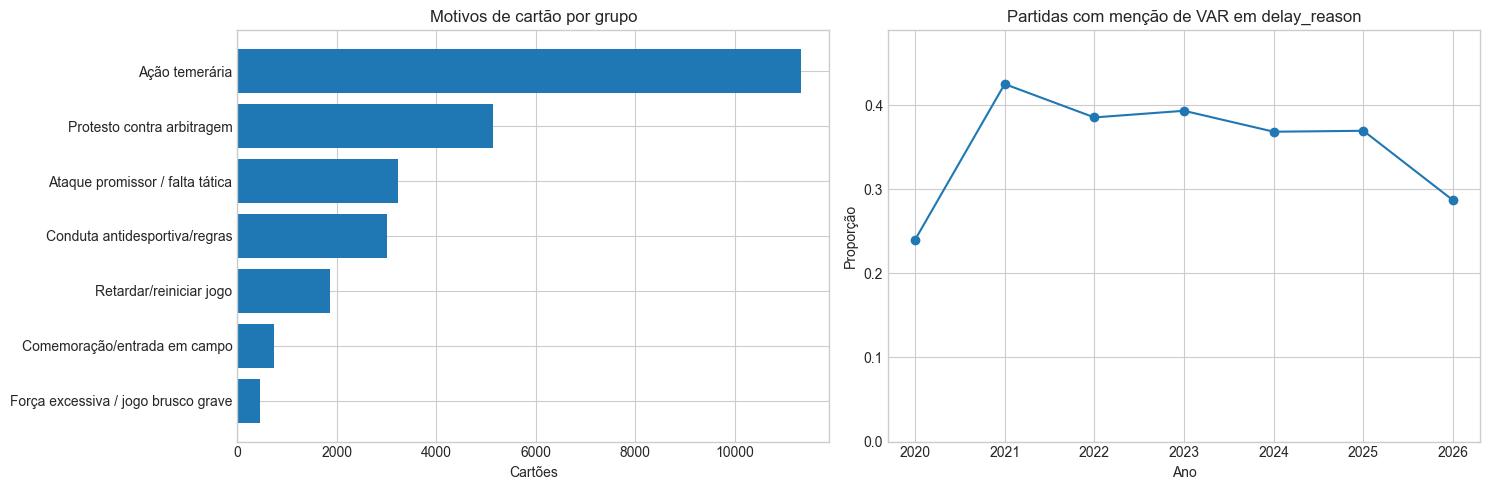

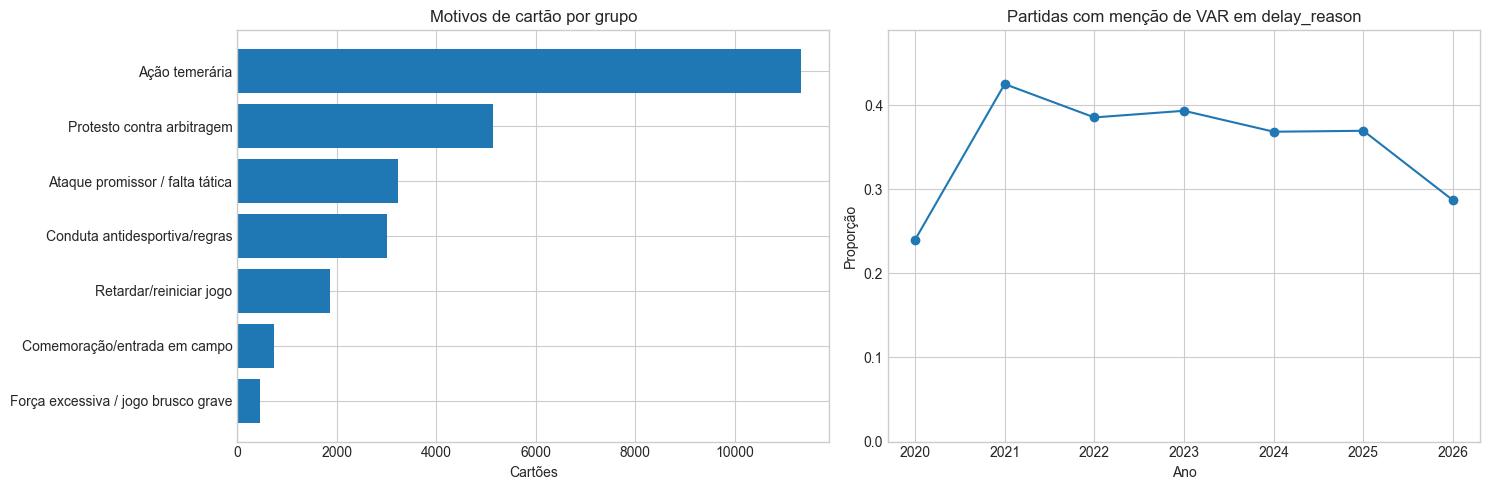

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

plot_card_summary = card_group_summary.sort_values("n_events", ascending=True)
axes[0].barh(plot_card_summary["card_reason_group"], plot_card_summary["n_events"])
axes[0].set_title("Motivos de cartão por grupo")
axes[0].set_xlabel("Cartões")

axes[1].plot(delay_var_by_year["year"], delay_var_by_year["pct_with_var_signal"], marker="o")
axes[1].set_title("Partidas com menção de VAR em delay_reason")
axes[1].set_xlabel("Ano")
axes[1].set_ylabel("Proporção")
axes[1].set_ylim(0, max(0.05, delay_var_by_year["pct_with_var_signal"].max() * 1.15))

plt.tight_layout()
fig

## **13. Salvamento dos Artefatos**

In [30]:
card_topic_summary_path = CARD_OUTPUT_DIR / "card_bertopic_topic_summary.csv"
card_topic_examples_path = CARD_OUTPUT_DIR / "card_bertopic_topic_examples.csv"
card_unique_topics_path = CARD_OUTPUT_DIR / "card_reason_unique_topics_labels.csv"
card_labeled_path = CARD_OUTPUT_DIR / "card_reasons_with_labels.csv"
card_group_summary_path = CARD_OUTPUT_DIR / "card_reason_group_summary.csv"
card_group_by_year_path = CARD_OUTPUT_DIR / "card_reason_group_by_year.csv"
card_group_by_type_path = CARD_OUTPUT_DIR / "card_reason_group_by_card_type.csv"
outros_audit_path = CARD_OUTPUT_DIR / "card_reason_outros_audit.csv"

delay_topic_summary_path = DELAY_OUTPUT_DIR / "delay_bertopic_topic_summary.csv"
delay_topic_examples_path = DELAY_OUTPUT_DIR / "delay_bertopic_topic_examples.csv"
delay_unique_topics_path = DELAY_OUTPUT_DIR / "delay_reason_unique_topics.csv"
delay_labeled_path = DELAY_OUTPUT_DIR / "delay_reasons_with_var.csv"
delay_var_by_year_path = DELAY_OUTPUT_DIR / "delay_var_by_year.csv"

card_topic_summary.to_csv(card_topic_summary_path, index=False)
card_topic_examples.to_csv(card_topic_examples_path, index=False)
card_text_counts.to_csv(card_unique_topics_path, index=False)
cards.to_csv(card_labeled_path, index=False)
card_group_summary.to_csv(card_group_summary_path, index=False)
card_group_by_year.to_csv(card_group_by_year_path)
card_group_by_type.to_csv(card_group_by_type_path)
outros_audit.to_csv(outros_audit_path, index=False)

delay_topic_summary.to_csv(delay_topic_summary_path, index=False)
delay_topic_examples.to_csv(delay_topic_examples_path, index=False)
delay_text_counts.to_csv(delay_unique_topics_path, index=False)
delays.to_csv(delay_labeled_path, index=False)
delay_var_by_year.to_csv(delay_var_by_year_path, index=False)

print("Arquivos salvos:")
for output_path in [
    card_topic_summary_path,
    card_topic_examples_path,
    card_unique_topics_path,
    card_labeled_path,
    card_group_summary_path,
    card_group_by_year_path,
    card_group_by_type_path,
    outros_audit_path,
    delay_topic_summary_path,
    delay_topic_examples_path,
    delay_unique_topics_path,
    delay_labeled_path,
    delay_var_by_year_path,
]:
    print(f"  {output_path}")

Arquivos salvos:
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_bertopic_topic_summary.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_bertopic_topic_examples.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_unique_topics_labels.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reasons_with_labels.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_group_summary.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_group_by_year.csv
  /Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/data/processed/semantic_reasons/card_reasons/card_reason_group_by_card_type.csv
  /Users/gcarninatto/D